# 03 Preprocessing Exploration

Eksplorasi strategi preprocessing audio sebelum masuk ke pipeline fine-tuning.
Tujuannya bukan langsung ke WER terbaik, tapi **cari kombinasi preprocessing yang paling stabil** — terutama untuk audio noisy seperti presentasi1.

**Yang dieksplorasi:**
- Noise reduction (stationary vs non-stationary)
- Amplitude normalization
- VAD parameter tuning (buat Whisper)
- Kombinasi: raw vs denoised vs normalized vs full pipeline

**Output notebook ini:**
Konfigurasi preprocessing terpilih → nanti dipindah ke `src/data/preprocess.py`

## 1. Install Dependencies

In [13]:
# !pip install faster-whisper noisereduce librosa soundfile jiwer matplotlib imageio-ffmpeg

## 2. Import & Konfigurasi

In [14]:
import os, re, time, subprocess, warnings
import numpy as np
import librosa
import librosa.display
import soundfile as sf
import noisereduce as nr
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from jiwer import wer
from faster_whisper import WhisperModel
import imageio_ffmpeg

warnings.filterwarnings('ignore')

BASE_DIR   = Path('..')
DATA_DIR   = BASE_DIR / 'data' / 'raw' / 'presentasi'
OUTPUT_DIR = BASE_DIR / 'data' / 'processed'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 16_000
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f'Device   : {DEVICE}')
print(f'Data dir : {DATA_DIR.resolve()}')
if DEVICE == 'cuda':
    print(f'GPU      : {torch.cuda.get_device_name(0)}')
    print(f'VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device   : cuda
Data dir : C:\Users\Aufii\Documents\Informatika\OTHERS\8. RISET-SKRIPSI\assistive-communicative\data\raw\presentasi
GPU      : NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM     : 6.4 GB


## 3. Load Data

In [ ]:
def normalize_text(text: str) -> str:
    text = text.lower().strip()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text

def convert_to_wav16k(audio_path: Path, output_dir: Path) -> Path:
    out = output_dir / (audio_path.stem + '_16k.wav')
    if out.exists():
        return out
    ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
    cmd = [ffmpeg, '-i', str(audio_path),
           '-ac', '1', '-ar', str(SAMPLE_RATE),
           str(out), '-y', '-loglevel', 'error']
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f'ffmpeg error: {r.stderr}')
    return out

# ── Load sessions ──────────────────────────────────────────────────────────────
AUDIO_EXTS = ['.wav', '.WAV', '.mp4', '.m4a', '.ogg', '.mp3', '.flac']
all_audio  = sorted([f for f in DATA_DIR.iterdir()
                     if f.suffix in AUDIO_EXTS and 'audio' in f.name.lower()])

sessions = []
for af in all_audio:
    gt_name = re.sub(r'\.(wav|WAV|mp4|m4a|ogg|mp3|flac)$', '.txt',
                     af.name.replace('audio', 'teks'))
    gt_path = DATA_DIR / gt_name
    if gt_path.exists():
        sessions.append({'audio': af, 'gt': gt_path})
        print(f'✅  {af.name:35s} → {gt_path.name}')
    else:
        print(f'⚠️  {af.name:35s} → ground truth tidak ditemukan, skip')

assert sessions, 'Tidak ada pasangan audio+ground truth ditemukan!'
print(f'\n→ {len(sessions)} sesi siap dievaluasi')

for s in sessions:
    s['wav']          = convert_to_wav16k(s['audio'], OUTPUT_DIR)
    s['audio_raw'], _ = librosa.load(str(s['wav']), sr=SAMPLE_RATE, mono=True)
    s['duration']     = len(s['audio_raw']) / SAMPLE_RATE
    s['gt_raw']       = s['gt'].read_text(encoding='utf-8')
    s['gt_norm']      = normalize_text(s['gt_raw'])
    print(f'  {s["audio"].name}: {s["duration"]:.1f}s '
          f'({s["duration"]/60:.1f} mnt) | GT: {len(s["gt_norm"].split())} kata')

✅  presentasi1-audio.WAV               → presentasi1-teks.txt
✅  presentasi2-audio.WAV               → presentasi2-teks.txt
✅  presentasi3-audio.wav               → presentasi3-teks.txt

→ 3 sesi siap dievaluasi
  presentasi1-audio.WAV: 90.7s (1.5 mnt) | GT: 193 kata
  presentasi2-audio.WAV: 122.7s (2.0 mnt) | GT: 270 kata
  presentasi3-audio.wav: 233.2s (3.9 mnt) | GT: 474 kata


## 4. Preprocessing Functions

In [ ]:
def normalize_amplitude(audio: np.ndarray, target_db: float = -20.0) -> np.ndarray:
    """
    Normalisasi RMS amplitude ke target dB.
    Penting biar semua audio punya loudness yang konsisten masuk ke model.
    """
    rms = np.sqrt(np.mean(audio ** 2))
    if rms == 0:
        return audio
    target_rms = 10 ** (target_db / 20)
    return audio * (target_rms / rms)


def denoise_stationary(audio: np.ndarray, sr: int = SAMPLE_RATE,
                       prop_decrease: float = 0.75) -> np.ndarray:
    """
    Noise reduction untuk noise stasioner (AC, kipas, hum konstan).
    prop_decrease: seberapa agresif noise ditekan (0.0-1.0).
    """
    return nr.reduce_noise(y=audio, sr=sr,
                           stationary=True,
                           prop_decrease=prop_decrease)


def denoise_nonstationary(audio: np.ndarray, sr: int = SAMPLE_RATE,
                          prop_decrease: float = 0.75) -> np.ndarray:
    """
    Noise reduction untuk noise non-stasioner (kursi geser, batuk, langkah kaki).
    Lebih agresif, tapi bisa artifact kalau audio sudah bersih.
    """
    return nr.reduce_noise(y=audio, sr=sr,
                           stationary=False,
                           prop_decrease=prop_decrease)


def full_preprocess(audio: np.ndarray, sr: int = SAMPLE_RATE,
                    prop_decrease: float = 0.75,
                    target_db: float = -20.0) -> np.ndarray:
    """
    Pipeline lengkap: denoise non-stationary → normalize amplitude.
    Ini yang akan dipakai di preprocess.py nanti kalau terbukti efektif.
    """
    audio = denoise_nonstationary(audio, sr, prop_decrease)
    audio = normalize_amplitude(audio, target_db)
    return audio


# Simpan versi preprocessing ke tiap session
for s in sessions:
    s['audio_stationary']    = denoise_stationary(s['audio_raw'])
    s['audio_nonstationary'] = denoise_nonstationary(s['audio_raw'])
    s['audio_normalized']    = normalize_amplitude(s['audio_raw'])
    s['audio_full']          = full_preprocess(s['audio_raw'])
    print(f'✅ {s["audio"].name} preprocessed')

✅ presentasi1-audio.WAV preprocessed
✅ presentasi2-audio.WAV preprocessed
✅ presentasi3-audio.wav preprocessed


## 5. Visualisasi — Waveform & Spectrogram

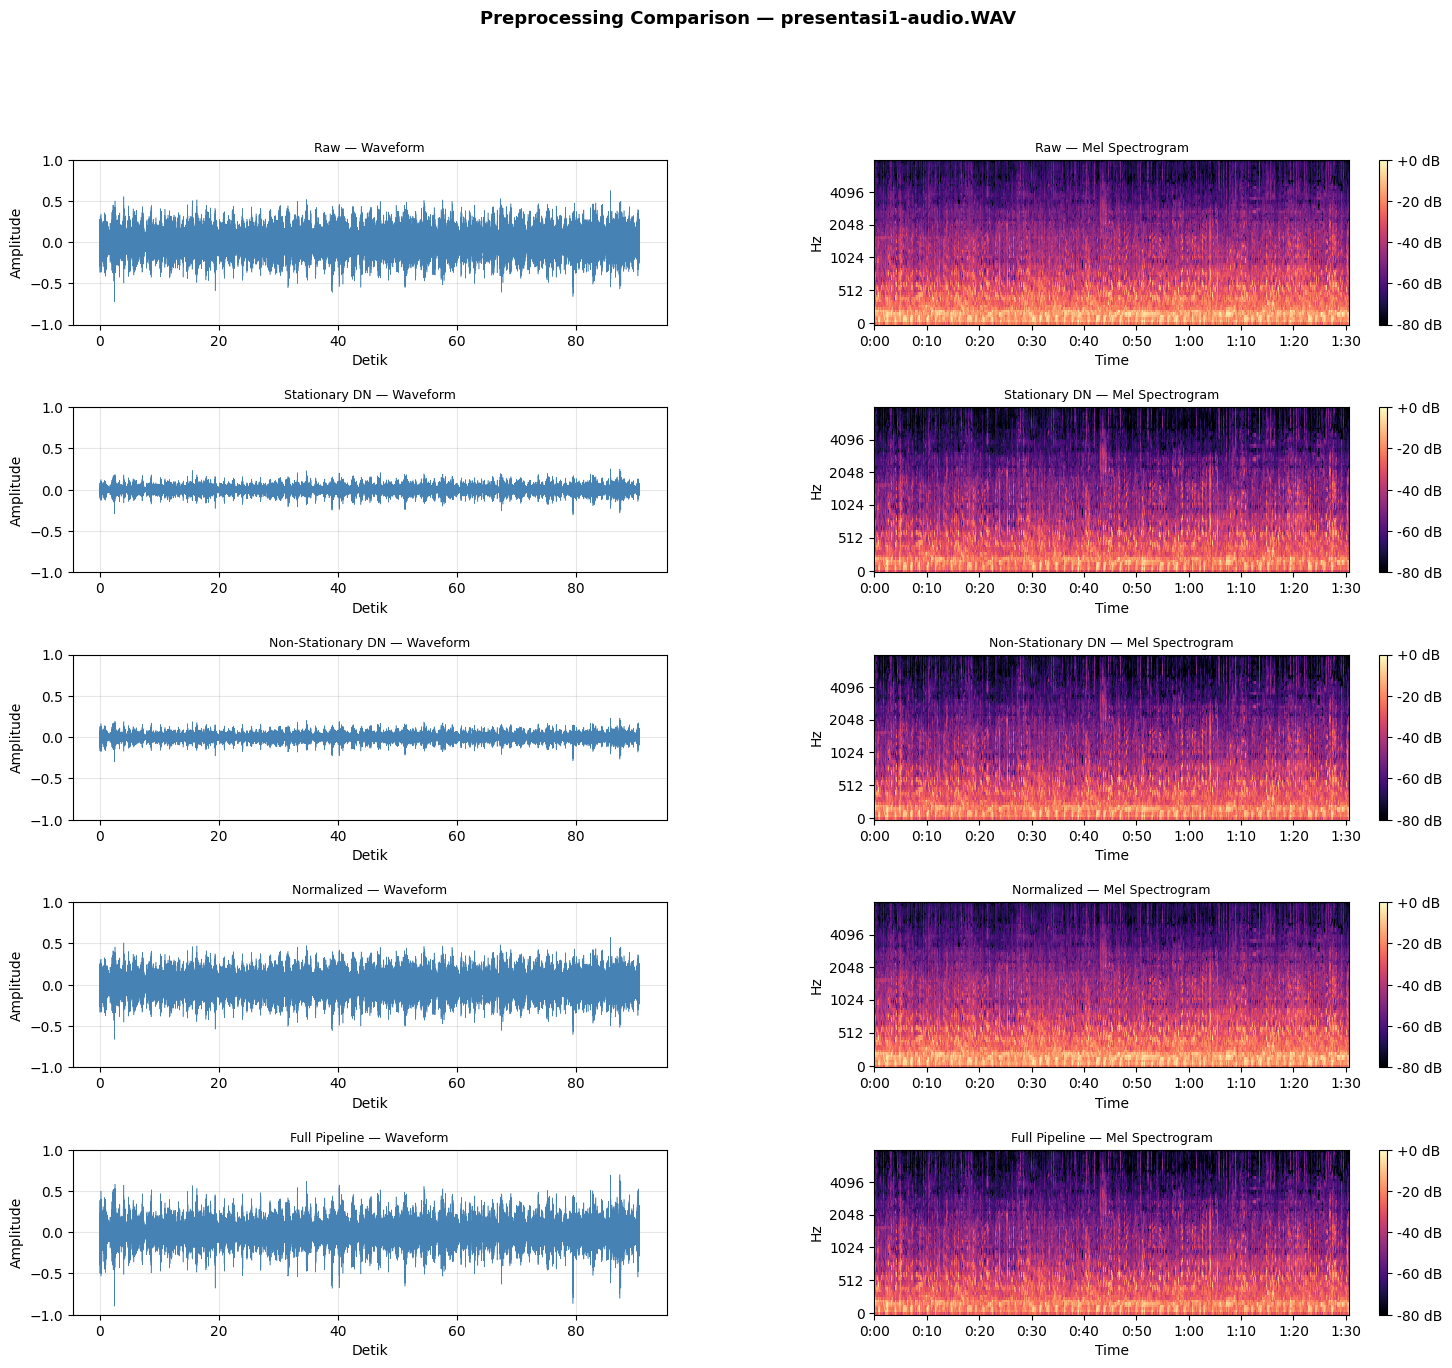

Plot disimpan.


In [ ]:
def plot_preprocessing_comparison(session: dict, sr: int = SAMPLE_RATE):
    variants = {
        'Raw'              : session['audio_raw'],
        'Stationary DN'    : session['audio_stationary'],
        'Non-Stationary DN': session['audio_nonstationary'],
        'Normalized'       : session['audio_normalized'],
        'Full Pipeline'    : session['audio_full'],
    }

    n = len(variants)
    fig = plt.figure(figsize=(18, n * 3))
    fig.suptitle(f'Preprocessing Comparison — {session["audio"].name}',
                 fontsize=13, fontweight='bold')
    gs = gridspec.GridSpec(n, 2, figure=fig, wspace=0.35, hspace=0.5)

    for i, (name, audio) in enumerate(variants.items()):
        # Waveform
        ax_wave = fig.add_subplot(gs[i, 0])
        ax_wave.plot(np.linspace(0, len(audio)/sr, len(audio)),
                     audio, linewidth=0.4, color='steelblue')
        ax_wave.set_title(f'{name} — Waveform', fontsize=9)
        ax_wave.set_xlabel('Detik')
        ax_wave.set_ylabel('Amplitude')
        ax_wave.set_ylim(-1, 1)
        ax_wave.grid(True, alpha=0.3)

        # Mel Spectrogram
        ax_spec = fig.add_subplot(gs[i, 1])
        S = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=80)
        S_db = librosa.power_to_db(S, ref=np.max)
        img = librosa.display.specshow(S_db, sr=sr, x_axis='time',
                                       y_axis='mel', ax=ax_spec)
        ax_spec.set_title(f'{name} — Mel Spectrogram', fontsize=9)
        fig.colorbar(img, ax=ax_spec, format='%+2.0f dB')

    plt.savefig(OUTPUT_DIR / f'preprocess_viz_{session["audio"].stem}.png',
                dpi=120, bbox_inches='tight')
    plt.show()
    print(f'Plot disimpan.')


# Ganti index untuk lihat sesi lain (0=presentasi1, 1=presentasi2, dst)
SESSION_IDX = 0
plot_preprocessing_comparison(sessions[SESSION_IDX])

## 6. Load Model (faster-whisper medium)

In [18]:
import gc
gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

model = WhisperModel('medium', device=DEVICE, compute_type='int8_float16' if DEVICE == 'cuda' else 'int8')
print('faster-whisper medium loaded.')

faster-whisper medium loaded.


## 7. Transcribe Helper & VAD Config

In [ ]:
VAD_CONFIGS = {
    'vad_default'  : dict(min_silence_duration_ms=300),
    'vad_strict'   : dict(min_silence_duration_ms=500, speech_pad_ms=200),
    'vad_very_strict': dict(min_silence_duration_ms=700, speech_pad_ms=300),
}

def transcribe(audio_array: np.ndarray,
               vad_params: dict,
               no_speech_threshold: float = 0.45,
               compression_ratio_threshold: float = 2.0) -> tuple[str, float]:
    tmp = OUTPUT_DIR / '_tmp_transcribe.wav'
    sf.write(str(tmp), audio_array, SAMPLE_RATE)

    t0 = time.time()
    segments, _ = model.transcribe(
        str(tmp),
        language='id',
        beam_size=5,
        condition_on_previous_text=True,
        vad_filter=True,
        vad_parameters=vad_params,
        no_speech_threshold=no_speech_threshold,
        compression_ratio_threshold=compression_ratio_threshold,
    )
    text = ' '.join(seg.text.strip() for seg in segments)
    elapsed = time.time() - t0
    tmp.unlink(missing_ok=True)
    return text, elapsed

print('Transcribe helper siap.')

Transcribe helper siap.


## 8. Experiment — Preprocessing × VAD

In [20]:
TECH_TERMS = [
    # CS Fundamentals
    "algoritma", "fungsi", "variabel", "array", "rekursi", "iterasi",
    "stack", "queue", "tree", "graph", "node", "edge", "branch",
    # OOP
    "class", "abstract", "constructor", "method", "attribute", "interface",
    "inheritance", "override", "polymorphism", "encapsulation", "instansiasi",
    "object", "diagram",
    # Graph & Algorithm
    "backtracking", "coloring", "pewarnaan", "simpul", "dead node",
    "depth first search", "dfs", "eliminasi",
    # CV/ML
    "preprocessing", "classification", "segmentasi", "ekstraksi",
    "dataset", "convolutional", "cnn", "feature extraction",
    "smoothing", "resize", "tekstur",
    # General CS
    "pipeline", "implementasi", "sistem", "parameter", "output", "input",
]

def compute_tter(hypothesis: str, reference: str, tech_terms: list[str]) -> dict:
    """Hitung TTER dari flat list tech terms."""
    hyp = hypothesis.lower()
    ref = reference.lower()
    terms_in_ref = [t for t in tech_terms if t in ref]
    if not terms_in_ref:
        return {"tter": 0.0, "total": 0, "missed": [], "correct": []}
    correct = [t for t in terms_in_ref if t in hyp]
    missed  = [t for t in terms_in_ref if t not in hyp]
    return {
        "tter"   : round(len(missed) / len(terms_in_ref) * 100, 2),
        "total"  : len(terms_in_ref),
        "correct": correct,
        "missed" : missed,
    }


PREPROCESSING_VARIANTS = {
    'raw'          : 'audio_raw',
    'stationary_dn': 'audio_stationary',
    'nonstat_dn'   : 'audio_nonstationary',
    'normalized'   : 'audio_normalized',
    'full_pipeline': 'audio_full',
}

results = []

for s in sessions:
    print(f'\n=== {s["audio"].name} ===')
    for prep_name, audio_key in PREPROCESSING_VARIANTS.items():
        for vad_name, vad_params in VAD_CONFIGS.items():
            label = f'{prep_name} + {vad_name}'
            audio  = s[audio_key]
            text, elapsed = transcribe(audio, vad_params)
            hyp_norm = normalize_text(text)

            word_err = wer(s['gt_norm'], hyp_norm) * 100
            tter_info = compute_tter(hyp_norm, s['gt_norm'], TECH_TERMS)
            rtf = elapsed / s['duration']

            results.append({
                'session'      : s['audio'].name,
                'preprocessing': prep_name,
                'vad_config'   : vad_name,
                'label'        : label,
                'wer'          : round(word_err, 2),
                'tter'         : tter_info['tter'],
                'tter_total'   : tter_info['total'],
                'tter_missed'  : ', '.join(tter_info['missed'][:5]),
                'rtf'          : round(rtf, 4),
                'text_full'    : text,
                'text_preview' : text[:120],
            })
            flag = '✅' if word_err < 30 else ('⚠️' if word_err < 60 else '❌')
            print(f'  {flag} {label:40s} WER={word_err:6.2f}%  TTER={tter_info["tter"]:6.2f}%  RTF={rtf:.4f}')



=== presentasi1-audio.WAV ===
  ❌ raw + vad_default                        WER= 69.95%  TTER= 75.00%  RTF=0.1583
  ❌ raw + vad_strict                         WER= 66.32%  TTER= 83.33%  RTF=0.1451
  ❌ raw + vad_very_strict                    WER= 70.47%  TTER= 83.33%  RTF=0.4779
  ❌ stationary_dn + vad_default              WER= 68.91%  TTER= 75.00%  RTF=0.2160
  ❌ stationary_dn + vad_strict               WER= 63.21%  TTER= 58.33%  RTF=0.1422
  ❌ stationary_dn + vad_very_strict          WER= 67.36%  TTER= 75.00%  RTF=0.2178
  ❌ nonstat_dn + vad_default                 WER= 65.28%  TTER= 66.67%  RTF=0.1638
  ❌ nonstat_dn + vad_strict                  WER= 63.21%  TTER= 83.33%  RTF=0.6711
  ❌ nonstat_dn + vad_very_strict             WER= 73.58%  TTER= 83.33%  RTF=0.3171
  ❌ normalized + vad_default                 WER= 72.02%  TTER= 75.00%  RTF=0.6793
  ❌ normalized + vad_strict                  WER= 70.47%  TTER= 58.33%  RTF=0.1738
  ❌ normalized + vad_very_strict             WER= 78.24%

## 9. Summary per Session

In [21]:
import pandas as pd

df = pd.DataFrame(results)

for session_name, grp in df.groupby('session'):
    print(f'\n── {session_name} ──')
    pivot = grp.pivot_table(
        index='preprocessing', columns='vad_config',
        values=['wer', 'tter'], aggfunc='mean'
    ).round(2)
    print(pivot.to_string())

print('\n── Rata-rata WER & TTER semua sesi ──')
avg = df.groupby(['preprocessing', 'vad_config'])[['wer', 'tter', 'rtf']].mean().round(2).reset_index()
avg = avg.sort_values('wer')
print(avg.to_string(index=False))



── presentasi1-audio.WAV ──
                     tter                                    wer                           
vad_config    vad_default vad_strict vad_very_strict vad_default vad_strict vad_very_strict
preprocessing                                                                              
full_pipeline       75.00      75.00           66.67       72.02      73.06           68.39
nonstat_dn          66.67      83.33           83.33       65.28      63.21           73.58
normalized          75.00      58.33           91.67       72.02      70.47           78.24
raw                 75.00      83.33           83.33       69.95      66.32           70.47
stationary_dn       75.00      58.33           75.00       68.91      63.21           67.36

── presentasi2-audio.WAV ──
                     tter                                    wer                           
vad_config    vad_default vad_strict vad_very_strict vad_default vad_strict vad_very_strict
preprocessing         

## 10. Visualisasi — WER Heatmap

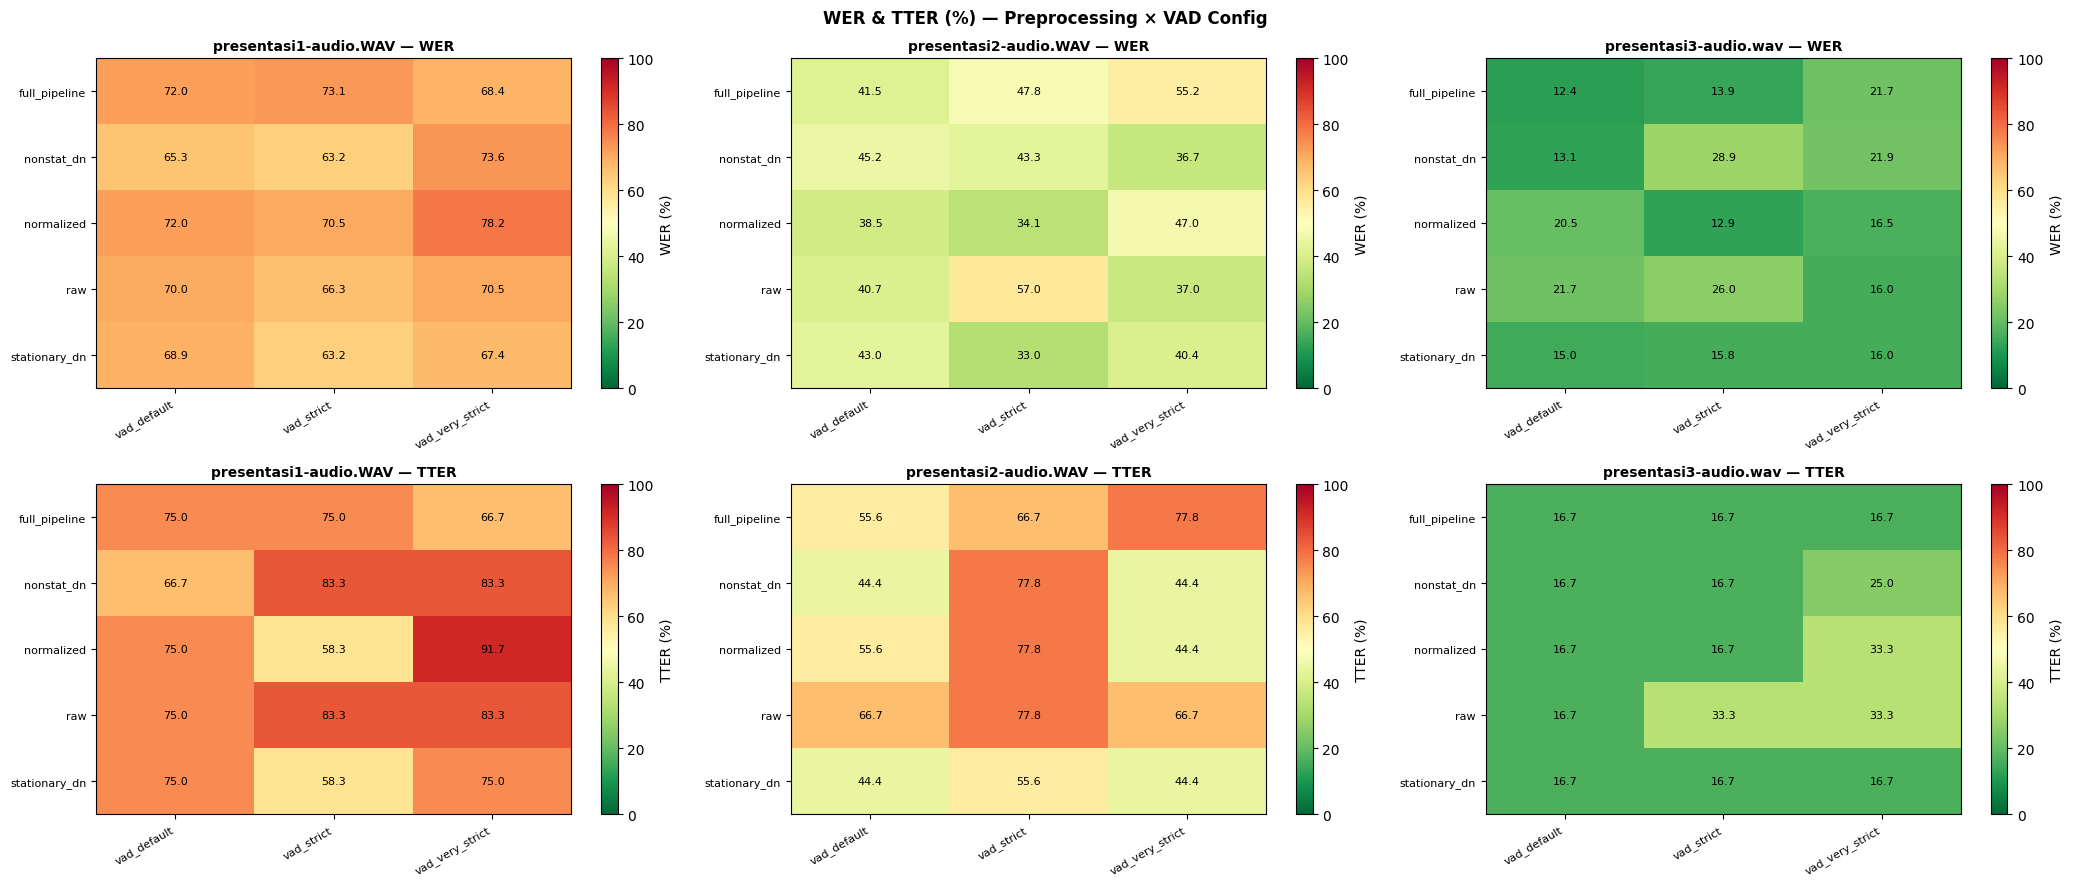

Heatmap disimpan.


In [22]:
n_sessions = len(sessions)
fig, axes = plt.subplots(2, n_sessions, figsize=(7 * n_sessions, 9))
if n_sessions == 1:
    axes = axes.reshape(2, 1)

for metric_idx, metric in enumerate(['wer', 'tter']):
    for ax, (session_name, grp) in zip(axes[metric_idx], df.groupby('session')):
        pivot = grp.pivot_table(
            index='preprocessing', columns='vad_config',
            values=metric, aggfunc='mean'
        ).round(1)
        im = ax.imshow(pivot.values, cmap='RdYlGn_r', aspect='auto', vmin=0, vmax=100)
        ax.set_xticks(range(len(pivot.columns)))
        ax.set_xticklabels(pivot.columns, rotation=30, ha='right', fontsize=8)
        ax.set_yticks(range(len(pivot.index)))
        ax.set_yticklabels(pivot.index, fontsize=8)
        ax.set_title(f'{session_name} — {metric.upper()}', fontsize=10, fontweight='bold')
        for r in range(pivot.shape[0]):
            for c in range(pivot.shape[1]):
                ax.text(c, r, f'{pivot.values[r, c]:.1f}', ha='center', va='center', fontsize=8)
        fig.colorbar(im, ax=ax, label=f'{metric.upper()} (%)')

fig.suptitle('WER & TTER (%) — Preprocessing × VAD Config', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'preprocess_wer_tter_heatmap.png', dpi=130, bbox_inches='tight')
plt.show()
print('Heatmap disimpan.')


## 11. Kesimpulan & Config Terpilih

In [23]:
best = avg.iloc[0]
print('━' * 55)
print('📋 KESIMPULAN PREPROCESSING')
print('━' * 55)
print(f'Kombinasi terbaik : {best["preprocessing"]} + {best["vad_config"]}')
print(f'WER rata-rata     : {best["wer"]:.2f}%')
print(f'TTER rata-rata    : {best["tter"]:.2f}%')
print(f'RTF rata-rata     : {best["rtf"]:.4f}')

baseline = avg[(avg['preprocessing']=='raw') & (avg['vad_config']=='vad_default')]
if len(baseline):
    b = baseline.iloc[0]
    print(f'\nBaseline (raw)    : WER={b["wer"]:.2f}%  TTER={b["tter"]:.2f}%  RTF={b["rtf"]:.4f}')
    print(f'Improvement WER   : {b["wer"] - best["wer"]:+.2f}%')
    print(f'Improvement TTER  : {b["tter"] - best["tter"]:+.2f}%')

print()
print('Config untuk preprocess.py:')
print(f'''
PREPROCESS_CONFIG = {{
    "denoise_method"     : "{best['preprocessing']}",
    "prop_decrease"      : 0.75,
    "target_db"          : -20.0,
    "vad_config"         : "{best['vad_config']}",
    "no_speech_threshold": 0.45,
    "compression_ratio"  : 2.0,
}}
''')


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
📋 KESIMPULAN PREPROCESSING
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Kombinasi terbaik : stationary_dn + vad_strict
WER rata-rata     : 37.33%
TTER rata-rata    : 43.52%
RTF rata-rata     : 0.2100

Baseline (raw)    : WER=44.14%  TTER=52.78%  RTF=0.1600
Improvement WER   : +6.81%
Improvement TTER  : +9.26%

Config untuk preprocess.py:

PREPROCESS_CONFIG = {
    "denoise_method"     : "stationary_dn",
    "prop_decrease"      : 0.75,
    "target_db"          : -20.0,
    "vad_config"         : "vad_strict",
    "no_speech_threshold": 0.45,
    "compression_ratio"  : 2.0,
}

